In [1]:
import os, json, math, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import make_grid as mg
importlib.reload(mg)        # pick up edits to make_grid.py without restarting the kernel
print("working in", os.getcwd())

working in /work/acd99/xbeach_sensitivity_d50


In [3]:
# fixed variables
HM0 = 2.0                 # wave height (m)
TP = 10.0                 # peak period (s)          
MAINANG = 225.0           # wave direction (deg, nautical)
DX = 5.0                  # grid spacing (m)       
FNYQ = 0.3                # spectrum cutoff (Hz)

N_CASES = 15
D50_RANGE_MM = (0.1, 1.0)                                       
d50_mm = np.geomspace(*D50_RANGE_MM, N_CASES)                   # evenly spaced on a log scale
D90_RATIO = 1.5                                                 # D90 = 1.5 x D50, as in the main study (0.3 / 0.2 mm)
base_dir = "xbeach_cases"

print(f"Hm0 = {HM0} m, Tp = {TP} s, mainang = {MAINANG} deg, dx = {DX} m")
print("D50 (mm):", ", ".join(f"{d:.3f}" for d in d50_mm))

Hm0 = 2.0 m, Tp = 10.0 s, mainang = 225.0 deg, dx = 5.0 m
D50 (mm): 0.100, 0.118, 0.139, 0.164, 0.193, 0.228, 0.268, 0.316, 0.373, 0.439, 0.518, 0.611, 0.720, 0.848, 1.000


In [3]:
os.makedirs(base_dir, exist_ok=True)     # never wiped: existing cases and results are kept
info = mg.grid_info(DX)
case_dirs, rows, n_new = [], [], 0
for d in d50_mm:
    folder = os.path.join(base_dir, f"run_d50_{d:.3f}mm")
    case_dirs.append(folder)
    os.makedirs(folder, exist_ok=True)
    d50, d90 = round(d / 1000, 7), round(D90_RATIO * d / 1000, 7)          # metres
    grid_path = os.path.join(folder, "grid.json")
    if not os.path.exists(grid_path):
        with open(grid_path, "w") as f:
            json.dump({"dx": DX, "output": "mean", "d50": d50, "d90": d90, **info}, f)
    jonswap_path = os.path.join(folder, "jonswap.txt")
    if not os.path.exists(jonswap_path):
        wave_input = f"""Hm0 = {HM0:.2f}
Tp = {TP:.2f}
mainang = {MAINANG:.2f}
gammajsp = 20.0
s = 16.0
fnyq = {FNYQ}
eps = 0.01         
dryslp = 1.0       
"""
        with open(jonswap_path, "w") as f:
            f.write(wave_input)
        n_new += 1
    rows.append({"folder": folder, "d50": d50, "d90": d90, "d50_mm": d, "hm0": HM0, "tp": TP,
                 "mainang": MAINANG, "dx": DX, **info})

assert len(set(case_dirs)) == len(case_dirs), "two D50 values round to the same folder name"
with open("case_list.txt", "w") as f:
    f.write("".join(f"{d}\n" for d in case_dirs))
pd.DataFrame(rows).to_csv("case_parameters.csv", index=False)
print(f"{len(case_dirs)} cases: {n_new} new, {len(case_dirs) - n_new} already existed")
print("Wrote case_list.txt and case_parameters.csv")

15 cases: 15 new, 0 already existed
Wrote case_list.txt and case_parameters.csv


In [6]:
MIN_PER_CASE_5M = 60
MEM_GB_5M = 4.5

hours = MIN_PER_CASE_5M / 60 * (5.0 / DX) ** 3
t_lim = max(1, math.ceil(2 * hours))
mem = max(16, 2 ** math.ceil(math.log2(MEM_GB_5M * (5.0 / DX) ** 2 * 1.5)))
print(f"~{hours:.1f} h per case; all {N_CASES} cases run at once, so the batch takes about as long as one case")
print("python post_process.py --case_list case_list.txt --write_pending pending.txt")
print("sbatch --array=0-$(( $(wc -l < pending.txt) - 1 )) " f"--time={t_lim:02d}:00:00 --mem={mem}G xbeach_array.sbatch pending.txt")
print("To compile:")
print("python post_process.py --case_list case_list.txt --out q_tot_summary_d50.csv")

~1.0 h per case; all 15 cases run at once, so the batch takes about as long as one case
python post_process.py --case_list case_list.txt --write_pending pending.txt
sbatch --array=0-$(( $(wc -l < pending.txt) - 1 )) --time=02:00:00 --mem=16G xbeach_array.sbatch pending.txt
To compile:
python post_process.py --case_list case_list.txt --out q_tot_summary_d50.csv


15 of 15 cases have results


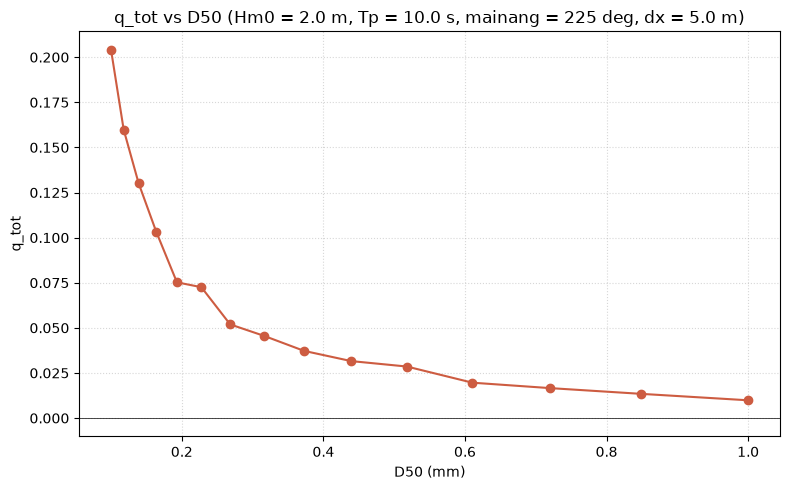

In [5]:
# run after batch run finishes
if not os.path.exists("q_tot_summary_d50.csv"):
    print("No q_tot_summary_d50.csv yet: run the batch and collect the results first.")
else:
    res = pd.read_csv("q_tot_summary_d50.csv").sort_values("d50")
    print(f"{len(res)} of {N_CASES} cases have results")
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(res["d50"] * 1000, res["q_tot"], "o-", color="#cd5c41")
    #ax.set_xscale("log")
    ax.set_xlabel("D50 (mm)")
    ax.set_ylabel("q_tot")
    ax.axhline(0, color="k", lw=0.5)
    ax.grid(True, which="both", linestyle=":", alpha=0.5)
    ax.set_title(f"q_tot vs D50 (Hm0 = {HM0} m, Tp = {TP} s, mainang = {MAINANG:g} deg, dx = {DX} m)")
    plt.tight_layout(); plt.show()